In [1]:
# Автоматическая перезагрузка модулей при изменении файлов

import lemmatizer_adapter as la
import os
import analysis as a
import time
import evaluation as e
import json
import summarizer as sm

# Test

# Тестирование функций split_sentences и tokens на 50 сложных текстах

# 50 сложных текстов с разнообразными проблемами
test_texts = [
    # 1-5: Сокращения
    "Правительство утвердило бюджет, т.е. все расходы были одобрены. Это важно, т.к. влияет на экономику.",
    "Нужно выполнить работу, т.д. и т.п. в срок. Однако, т.к. сроки сжаты, это невозможно.",
    "Компания ООО «Ромашка» получила прибыль 500 млн. руб. в 2023 г. Это рекордный показатель.",
    "Ул. Ленина, д. 15, кв. 42 — адрес офиса. Пер. Ногина, д. 3 — филиал.",
    "См. рис. 1 на стр. 15. Подробное описание — в приложении А.",

    # 6-10: Инициалы и ФИО
    "И.И. Иванов и А.С. Петров встретились в Москве. Они обсуждали проект.",
    "Министр финансов А.Г. Силуанов выступил с докладом. Его поддержал Д.А. Медведев.",
    "В.В. Путин подписал указ. Пресс-секретарь Д.С. Песков прокомментировал решение.",
    "А.С. Пушкин и М.Ю. Лермонтов — великие русские поэты. Их произведения известны во всём мире.",
    "Профессор И.П. Павлов получил Нобелевскую премию в 1904 г. за работу по физиологии пищеварения.",

    # 11-15: Числа и единицы измерения
    "Бюджет составил 15 млрд. руб. Расходы выросли на 20% по сравнению с 2022 г.",
    "Компания заработала 500 тыс. долл. прибыли. Это на 15% больше, чем в прошлом году.",
    "Население города — 2,5 млн. человек. Площадь — 300 кв. км.",
    "Температура упала до -25°C. Скорость ветра достигла 15 м/с.",
    "Инфляция составила 8,5% в 2023 г. ВВП вырос на 3,2%.",

    # 16-20: Разные знаки препинания
    "Кто это сделал? Никто не знал! Но все догадались…",
    "Он спросил: «Ты придёшь?» Она ответила: «Не знаю…»",
    "Внимание! Важное объявление! Пожалуйста, прочитайте внимательно.",
    "Что? Где? Когда? — популярная телепередача. Она выходит с 1975 г.",
    "Да… Нет… Может быть… Я не уверен.",

    # 21-25: Кавычки и цитаты
    "Президент сказал: «Мы продолжим реформы». Оппозиция ответила: «Это популизм».",
    "Компания «Газпром» отчиталась о прибыли. «Роснефть» показала рекордные результаты.",
    "В статье «Экономика России» автор утверждает, что рост продолжится. Критики называют это «оптимизмом».",
    "Он произнёс: «Всё будет хорошо». Она добавила: «Надеюсь…»",
    "Газета «Коммерсантъ» опубликовала материал. Журнал «Эксперт» его прокомментировал.",

    # 26-30: Аббревиатуры
    "РФ и США подписали договор. ЕС выразил поддержку. ООН провела заседание.",
    "ООО «Ромашка» и ЗАО «Василёк» заключили сделку. ПАО «Газпром» выступило гарантом.",
    "МГУ им. М.В. Ломоносова — ведущий вуз России. СПбГУ — второй по значимости.",
    "ВВЦ (Выставка достижений народного хозяйства) открылась после реконструкции. ВДНХ работает ежедневно.",
    "ГКЧП (Государственный комитет по чрезвычайному положению) был создан в 1991 г. Его деятельность прекратилась через 3 дня.",

    # 31-35: Сложные сокращения
    "Т.е. это означает, что т.н. «реформа» не удалась. Т.ч. результаты плачевные.",
    "В 1990-х гг. экономика переживала кризис. В 2000-х гг. начался рост.",
    "Проф., д-р наук И.И. Иванов выступил на конференции. Его доклад был высоко оценён.",
    "Канд. экон. наук А.А. Петров защитил диссертацию в 2020 г. Теперь он доц.",
    "Средняя з/п составила 50 тыс. руб. Максимальная — 200 тыс. руб.",

    # 36-40: Многоточия и паузы
    "Он задумался… Потом сказал: «Не знаю… Может быть… Но вряд ли…»",
    "Текст обрывается… Продолжение следует… Не пропустите!",
    "Это было давно… Очень давно… В 1990 г.… Или в 1991 г.? Точно не помню.",
    "Слова… Слова… Только слова… Где же действия?",
    "Начало… Середина… Конец… Вот и всё.",

    # 41-45: Смешанные случаи
    "Министерство финансов РФ представило проект бюджета на 2024 г. Основные расходы, т.е. около 70% всех трат, пойдут на социальные нужды. Министр А.Г. Силуанов отметил, что это важно, т.к. нужно поддержать граждан.",
    "Компания ООО «ТехноПром» получила кредит 500 млн. руб. в Сбербанке. Ген. директор И.И. Иванов подписал договор. Это крупнейшая сделка за последние 5 лет.",
    "В 1990 г. родился известный учёный. В 2010 г. он окончил МГУ. В 2015 г. защитил диссертацию. Теперь он проф. и ведёт исследования.",
    "Температура упала до -30°C. Скорость ветра — 20 м/с. МЧС предупреждает: возможна метель! Будьте осторожны!",
    "Газета «Коммерсантъ» сообщает: правительство утвердило бюджет на 2024 г. Расходы составят 35 трлн. руб. Это на 10% больше, чем в 2023 г.",

    # 46-50: Очень сложные случаи
    "Т.е. т.д. т.п. — всё это сокращения. Их нужно правильно обрабатывать. Иначе текст разобьётся неправильно!",
    "И.И. Иванов, А.А. Петров и С.С. Сидоров встретились в 15:00. Они обсуждали проект до 18:00. Потом пошли в кафе.",
    "ООО «Ромашка» (ИНН 1234567890) и ЗАО «Василёк» (ОГРН 9876543210) заключили договор на сумму 1 млн. руб. Срок оплаты — 30 дней.",
    "В 1990-х гг. (1990-1999 гг.) экономика переживала кризис. В 2000-х гг. (2000-2009 гг.) начался рост. В 2010-х гг. (2010-2019 гг.) — стагнация.",
    "Проф., д-р физ.-мат. наук И.И. Иванов (р. в 1950 г.) получил премию в 2020 г. Его ученик, канд. наук А.А. Петров, продолжает исследования.",
]

print("=" * 100)
print("ТЕСТИРОВАНИЕ split_sentences И tokens НА 50 СЛОЖНЫХ ТЕКСТАХ")
print("=" * 100)

for idx, text in enumerate(test_texts, 1):
    print(f"\n{'='*100}")
    print(f"ТЕКСТ №{idx}")
    print(f"{'='*100}")
    print(f"\nОРИГИНАЛ:\n{text}\n")

    # 1. Разбиение на предложения
    sentences = sm.split_sentences(text)
    print(f"РАЗБИЕНИЕ НА ПРЕДЛОЖЕНИЯ ({len(sentences)} шт.):")
    for i, sent in enumerate(sentences, 1):
        print(f"  {i}. {sent}")

    # 2. Токенизация каждого предложения
    print(f"\nТОКЕНИЗАЦИЯ:")
    for i, sent in enumerate(sentences, 1):
        toks = sm.tokens(sent)
        print(f"  Предложение {i}: {toks}")

    print(f"\n{'-'*100}")

print("\n" + "=" * 100)
print("ТЕСТИРОВАНИЕ ЗАВЕРШЕНО")
print("=" * 100)

ТЕСТИРОВАНИЕ split_sentences И tokens НА 50 СЛОЖНЫХ ТЕКСТАХ

ТЕКСТ №1

ОРИГИНАЛ:
Правительство утвердило бюджет, т.е. все расходы были одобрены. Это важно, т.к. влияет на экономику.

РАЗБИЕНИЕ НА ПРЕДЛОЖЕНИЯ (2 шт.):
  1. Правительство утвердило бюджет, т.е. все расходы были одобрены.
  2. Это важно, т.к. влияет на экономику.

ТОКЕНИЗАЦИЯ:
Загрузка модели из C:\Users\Pedant\Desktop\ru-text-summarization-lab3\lab1_model.pkl... готово!
  Предложение 1: ['правительство', 'утвердить', 'бюджет', 'расход', 'одобрить']
  Предложение 2: ['важно', 'влиять', 'экономика']

----------------------------------------------------------------------------------------------------

ТЕКСТ №2

ОРИГИНАЛ:
Нужно выполнить работу, т.д. и т.п. в срок. Однако, т.к. сроки сжаты, это невозможно.

РАЗБИЕНИЕ НА ПРЕДЛОЖЕНИЯ (2 шт.):
  1. Нужно выполнить работу, т.д. и т.п. в срок.
  2. Однако, т.к. сроки сжаты, это невозможно.

ТОКЕНИЗАЦИЯ:
  Предложение 1: ['нужно', 'выполнить', 'работа', 'срок']
  Предложение 2: ['с

In [2]:
# Тест
test_words = ['утвердить', 'профессиональный', 'россия', 'написать', 'теннисист', 'разъяснить', 'частичный', 'фармацевт', 'официант', 'яхтсмен', 'новый', 'разработать', 'обнародовать']
lemmas = la.lemmatize_words(test_words)
print(f"Вход: {test_words}")
print(f"Леммы: {lemmas}")

Вход: ['утвердить', 'профессиональный', 'россия', 'написать', 'теннисист', 'разъяснить', 'частичный', 'фармацевт', 'официант', 'яхтсмен', 'новый', 'разработать', 'обнародовать']
Леммы: [('утвердить', 'V'), ('профессиональный', 'A'), ('россия', 'S'), ('написать', 'V'), ('теннисист', 'S'), ('разъяснить', 'V'), ('частичный', 'A'), ('фармацевт', 'S'), ('официант', 'S'), ('яхтсмен', 'S'), ('новый', 'A'), ('разработать', 'V'), ('обнародовать', 'V')]


In [3]:
MAX_LEN = 300

print("=" * 80)
print("ТЕСТИРОВАНИЕ ФУНКЦИИ summarize (Лимит: 300 символов)")
print("=" * 80)

for idx, text in enumerate(test_texts, 1):
    print(f"\n{'='*80}")
    print(f"ПРИМЕР №{idx}")
    print(f"{'='*80}")

    print(f"ОРИГИНАЛ ({len(text)} симв.):\n{text}\n")

    # Вызываем функцию summar для одного текста
    summary = sm.summarize(text, MAX_LEN)

    print(f"РЕФЕРАТ ({len(summary)} симв.):\n{summary}\n")

    # Проверка: не превышен ли лимит
    if len(summary) <= MAX_LEN:
        print(" ЛИМИТ СОБЛЮДЕН")
    else:
        print(" ОШИБКА: Превышен лимит в 300 символов!")

    # Проверка: не является ли это тривиальным решением (первыми 300 символами)
    if summary == text[:MAX_LEN] and len(text) > MAX_LEN:
        print("️ ВНИМАНИЕ: Результат совпадает с первыми 300 символами (тривиальное решение)")
    else:
        print(" НЕ ТРИВИАЛЬНОЕ РЕШЕНИЕ (алгоритм выбрал лучшие предложения)")

print("\n" + "=" * 80)
print("ТЕСТИРОВАНИЕ ЗАВЕРШЕНО")
print("=" * 80)

ТЕСТИРОВАНИЕ ФУНКЦИИ summarize (Лимит: 300 символов)

ПРИМЕР №1
ОРИГИНАЛ (100 симв.):
Правительство утвердило бюджет, т.е. все расходы были одобрены. Это важно, т.к. влияет на экономику.

РЕФЕРАТ (100 симв.):
Правительство утвердило бюджет, т.е. все расходы были одобрены. Это важно, т.к. влияет на экономику.

 ЛИМИТ СОБЛЮДЕН
 НЕ ТРИВИАЛЬНОЕ РЕШЕНИЕ (алгоритм выбрал лучшие предложения)

ПРИМЕР №2
ОРИГИНАЛ (85 симв.):
Нужно выполнить работу, т.д. и т.п. в срок. Однако, т.к. сроки сжаты, это невозможно.

РЕФЕРАТ (77 симв.):
Нужно выполнить работу, т.д. и т.п. в срок. Т.к. сроки сжаты, это невозможно.

 ЛИМИТ СОБЛЮДЕН
 НЕ ТРИВИАЛЬНОЕ РЕШЕНИЕ (алгоритм выбрал лучшие предложения)

ПРИМЕР №3
ОРИГИНАЛ (89 симв.):
Компания ООО «Ромашка» получила прибыль 500 млн. руб. в 2023 г. Это рекордный показатель.

РЕФЕРАТ (89 симв.):
Компания ООО «Ромашка» получила прибыль 500 млн. руб. в 2023 г. Это рекордный показатель.

 ЛИМИТ СОБЛЮДЕН
 НЕ ТРИВИАЛЬНОЕ РЕШЕНИЕ (алгоритм выбрал лучшие предложения)

ПРИМЕ

In [4]:
# Загружаем реальные данные из датасета Gazeta
print("Загрузка данных из датасета...")
with open("gazeta/test_texts.json", "r", encoding="utf-8") as f:
    real_texts = json.load(f)
with open("gazeta/test_refs.json", "r", encoding="utf-8") as f:
    real_refs = json.load(f)

# Берем только первые 10 примеров для быстрого и наглядного теста
sample_texts = real_texts[:10]
sample_refs = real_refs[:10]

MAX_LEN = 300

print("=" * 80)
print("ТЕСТИРОВАНИЕ НА 10 РЕАЛЬНЫХ ПРИМЕРАХ ИЗ ДАТАСЕТА GAZETA")
print("=" * 80)

for idx in range(10):
    text = sample_texts[idx]
    ref = sample_refs[idx]

    print(f"\n{'='*80}")
    print(f"ПРИМЕР №{idx + 1}")
    print(f"{'='*80}")

    preview_len = 400 if len(text) > 400 else len(text)
    print(f" ОРИГИНАЛ ({len(text)} симв.):\n{text[:preview_len]}{'...' if len(text) > 400 else ''}\n")

    #  Вызываем правильную функцию summarize
    summary = sm.summarize(text, max_len=MAX_LEN)

    print(f" РЕФЕРАТ ({len(summary)} симв.):\n{summary}\n")

    print(f" ЭТАЛОН ЧЕЛОВЕКА ({len(ref)} симв.):\n{ref}\n")

    # Проверка лимита
    if len(summary) <= MAX_LEN:
        print(" ЛИМИТ (300 симв.) СОБЛЮДЕН")
    else:
        print(" ОШИБКА: Превышен лимит в 300 символов!")

    # Проверка на тривиальность
    if summary == text[:MAX_LEN] and len(text) > MAX_LEN:
        print("️ ВНИМАНИЕ: Результат совпадает с первыми 300 символами (тривиальное решение)")
    else:
        print(" НЕ ТРИВИАЛЬНОЕ РЕШЕНИЕ")

    # Считаем ROUGE для этого конкретного примера
    score = e.evaluate([summary], [ref], MAX_LEN)
    print(f" ROUGE для этого примера: R1={score['rouge1']:.3f}, R2={score['rouge2']:.3f}, RL={score['rougeL']:.3f}")

print("\n" + "=" * 80)
print("ТЕСТИРОВАНИЕ 10 ПРИМЕРОВ УСПЕШНО ЗАВЕРШЕНО")
print("=" * 80)

# В Примере 6 в конце реферата есть обрывок цитаты: «Налетай, расхватывай!»). Это происходит потому, что в этом предложении были уникальные слова, которые дали ему высокий балл по TF-IDF, а MMR-штраф не счел его достаточно похожим на предыдущие

Загрузка данных из датасета...
ТЕСТИРОВАНИЕ НА 10 РЕАЛЬНЫХ ПРИМЕРАХ ИЗ ДАТАСЕТА GAZETA

ПРИМЕР №1
 ОРИГИНАЛ (3753 симв.):
На этих выходных в Берлине прошли крупные акции протеста против введенных для борьбы с коронавирусом ограничений. Демонстранты скандировали «Путин!» По словам депутата городской палаты представителей Гуннара Линдеманна («Альтернатива для Германии»), люди выкрикивали фамилию российского президента из уважения к нему. В комментарии РИА «Новости» немецкий политик отметил, что среди населения Германии...

 РЕФЕРАТ (299 симв.):
Российское посольство находится по улице Унтер-ден-Линден. Но на улице Унтер-ден-Линден, почти перед российским посольством были насильственные действия, там кидали бутылки и камни, были раненые, задержано более 200 человек — там было необходимо полицейское подкрепление, и произошла переброска сил.

 ЭТАЛОН ЧЕЛОВЕКА (369 симв.):
Протестующие против антикоронавирусных мер немцы скандировали имя российского президента, потому что уважают его. Такое 

 ПЕРВИЧНЫЙ АНАЛИЗ ДАТАСЕТА: validation

 Загрузка данных...
   Размер файла: 48.25 МБ
   Количество текстов: 6369
   Количество эталонов: 6369

 СТАТИСТИКА ПО ТЕКСТАМ

    Длина текста (символы):
      Минимум:    2177.0 
      Q1 (25%):   3706.0 
      Медиана:    4059.0 
      Среднее:    4358.4 
      Q3 (75%):   4591.0 
      Максимум:   9741.0 
      Стд.откл.:  1231.9 

    Длина текста (слова):
      Минимум:    274.0 
      Q1 (25%):   498.0 
      Медиана:    545.0 
      Среднее:    588.1 
      Q3 (75%):   622.0 
      Максимум:   1306.0 
      Стд.откл.:  163.8 

    Количество предложений:
      Минимум:    13.0 шт.
      Q1 (25%):   29.0 шт.
      Медиана:    34.0 шт.
      Среднее:    36.1 шт.
      Q3 (75%):   41.0 шт.
      Максимум:   102.0 шт.
      Стд.откл.:  11.1 шт.

    Средняя длина предложения:
      Минимум:    7.0 слов
      Q1 (25%):   14.7 слов
      Медиана:    16.5 слов
      Среднее:    16.7 слов
      Q3 (75%):   18.5 слов
      Максимум:   42.2 слов
 

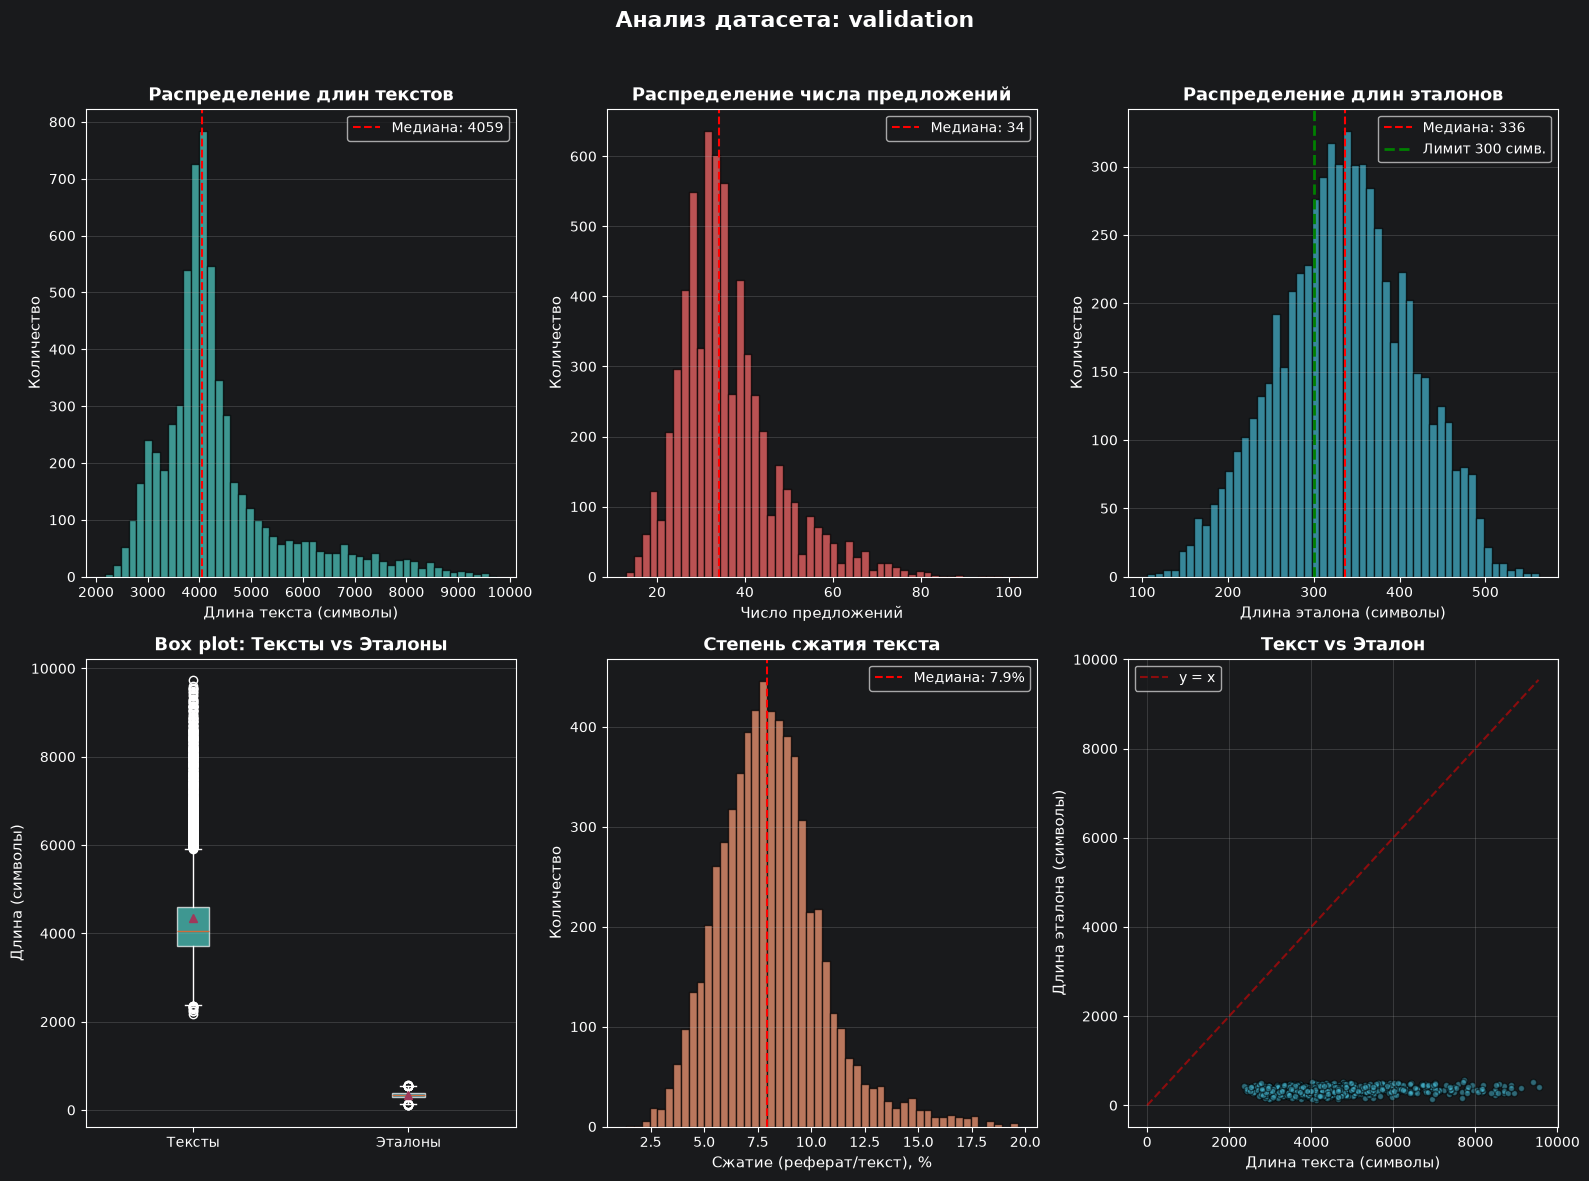


 ИТОГОВАЯ СВОДКА

   Датасет:                validation
   Количество текстов:     6369
   Размер файла:           48.25 МБ
   Средняя длина текста:   4358 симв. / 588 слов
   Медиана предложений:    34
   Средняя длина эталона:  336 симв.
   Среднее сжатие:         8.1%



In [5]:
# Пути к файлам
VAL_TEXTS = "gazeta/validation_texts.json"
VAL_REFS = "gazeta/validation_refs.json"
TEST_TEXTS = "gazeta/test_texts.json"
TEST_REFS = "gazeta/test_refs.json"

# Анализ валидации
if os.path.exists(VAL_TEXTS):
    a.analyze_dataset(VAL_TEXTS, VAL_REFS, dataset_name="validation")

 ПЕРВИЧНЫЙ АНАЛИЗ ДАТАСЕТА: test

 Загрузка данных...
   Размер файла: 52.55 МБ
   Количество текстов: 6793
   Количество эталонов: 6793

 СТАТИСТИКА ПО ТЕКСТАМ

    Длина текста (символы):
      Минимум:    1485.0 
      Q1 (25%):   3531.0 
      Медиана:    4018.0 
      Среднее:    4446.1 
      Q3 (75%):   4994.0 
      Максимум:   9841.0 
      Стд.откл.:  1393.5 

    Длина текста (слова):
      Минимум:    194.0 
      Q1 (25%):   474.0 
      Медиана:    537.0 
      Среднее:    595.1 
      Q3 (75%):   667.0 
      Максимум:   1270.0 
      Стд.откл.:  184.9 

    Количество предложений:
      Минимум:    12.0 шт.
      Q1 (25%):   28.0 шт.
      Медиана:    33.0 шт.
      Среднее:    35.7 шт.
      Q3 (75%):   41.0 шт.
      Максимум:   113.0 шт.
      Стд.откл.:  11.7 шт.

    Средняя длина предложения:
      Минимум:    6.3 слов
      Q1 (25%):   15.0 слов
      Медиана:    16.9 слов
      Среднее:    17.0 слов
      Q3 (75%):   18.9 слов
      Максимум:   35.8 слов
      С

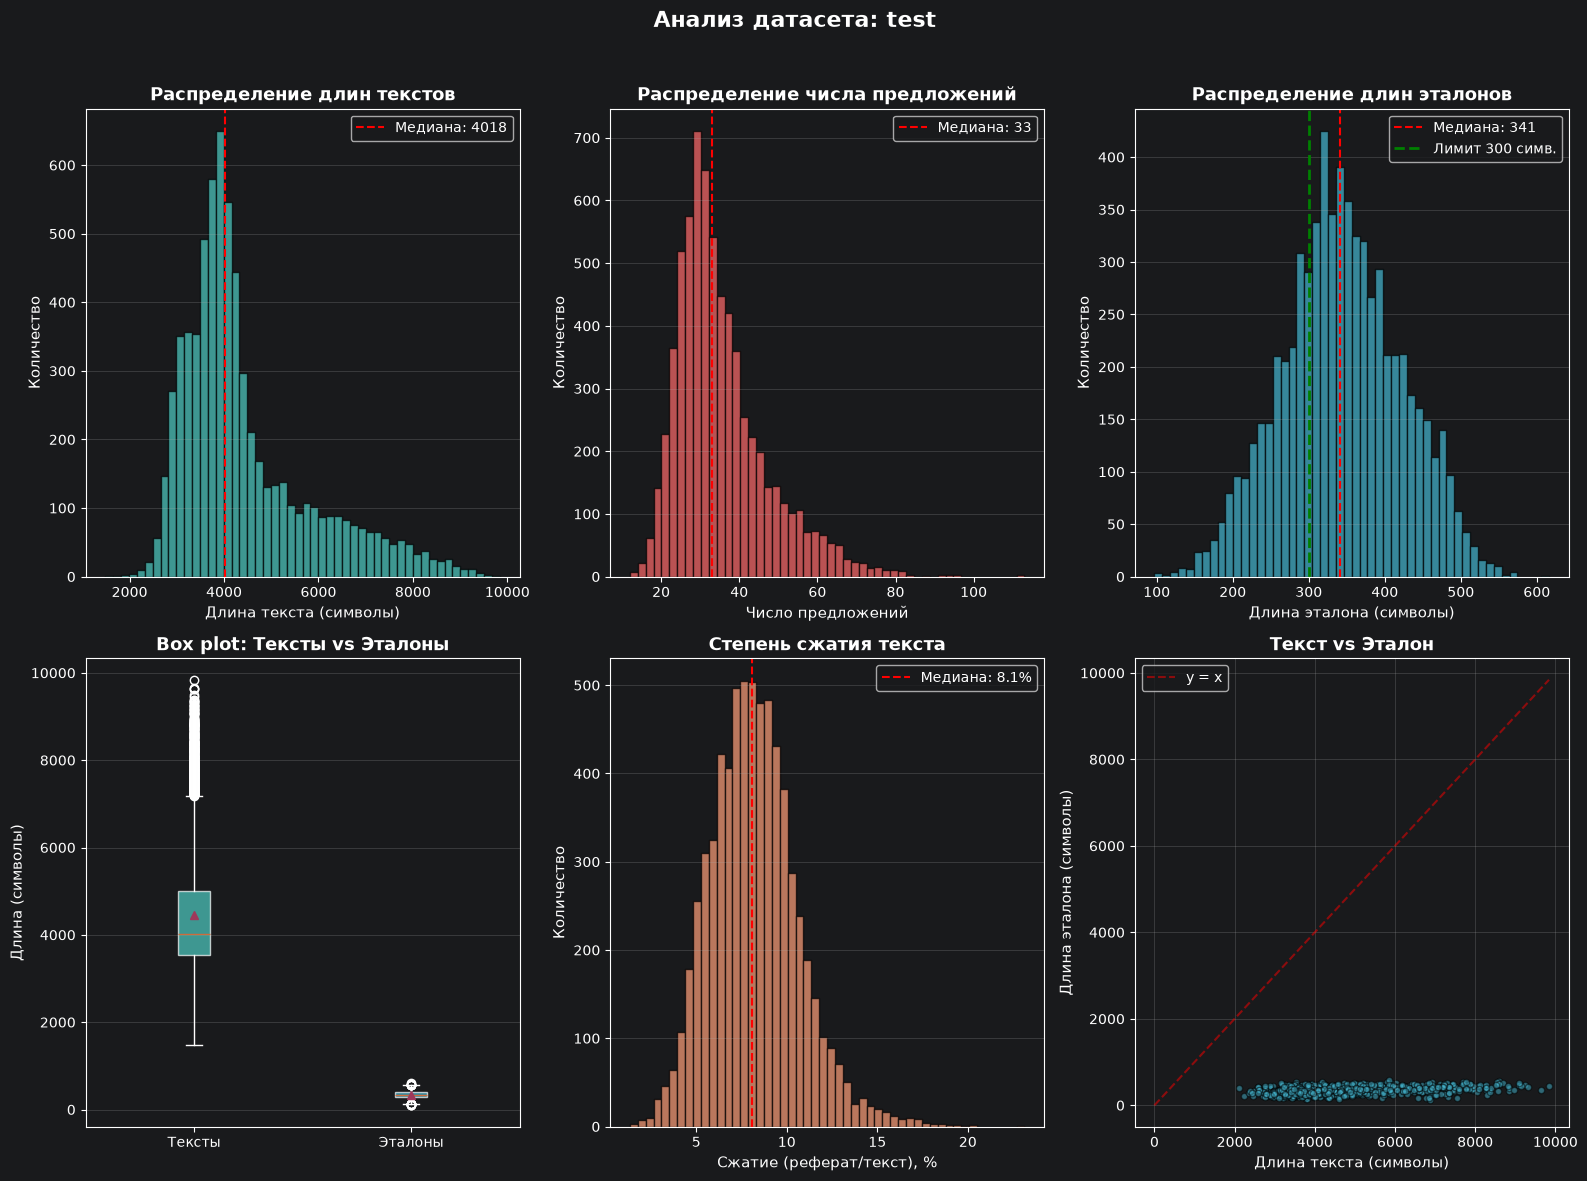


 ИТОГОВАЯ СВОДКА

   Датасет:                test
   Количество текстов:     6793
   Размер файла:           52.55 МБ
   Средняя длина текста:   4446 симв. / 595 слов
   Медиана предложений:    33
   Средняя длина эталона:  343 симв.
   Среднее сжатие:         8.2%



In [6]:
# Анализ теста
if os.path.exists(TEST_TEXTS):
    a.analyze_dataset(TEST_TEXTS, TEST_REFS, dataset_name="test")

 СРАВНЕНИЕ ДАТАСЕТОВ: validation vs test

Метрика                        validation           test                
----------------------------------------------------------------------
Количество текстов             6369                 6793                
Средняя длина (симв.)          4358.4               4446.1              
Медиана длины (симв.)          4059.0               4018.0              
Среднее число предложений      36.1                 35.7                
Медиана предложений            34.0                 33.0                

 Анализ схожести распределений:
   Разница средних длин:     1.99%
   Разница медиан:           1.02%
    Распределения очень похожи - выборки репрезентативны


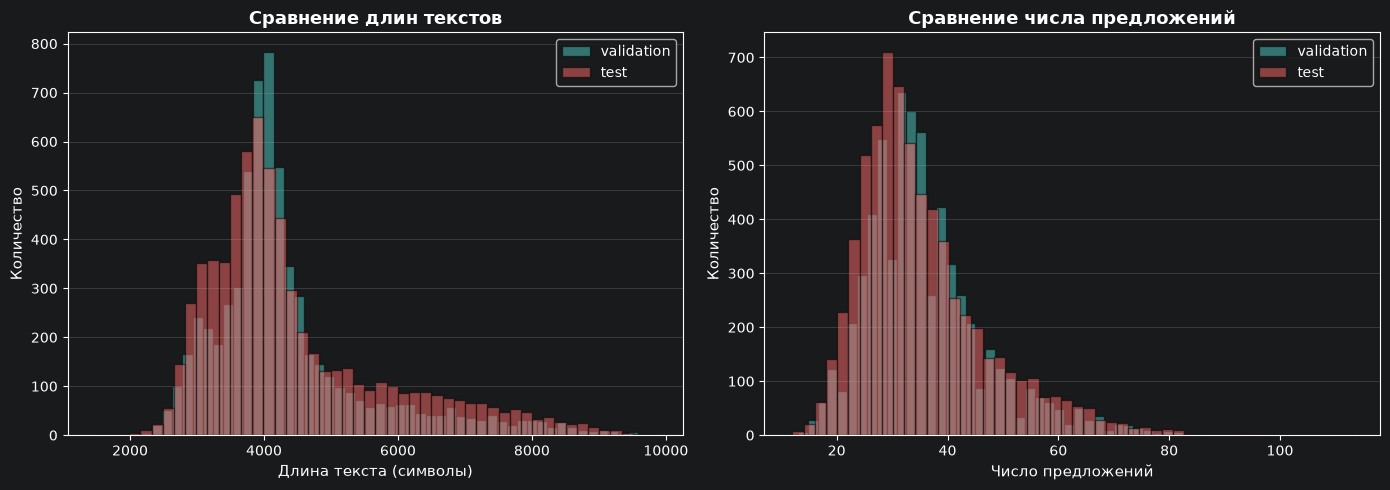

In [7]:
# Сравнение двух датасетов
if os.path.exists(VAL_TEXTS) and os.path.exists(TEST_TEXTS):
    a.compare_datasets(VAL_TEXTS, TEST_TEXTS, "validation", "test")

In [8]:
# Подбор гиперпараметров

 # Сетка: только 4 основных параметра
grid = {
    "w_tr": [0.3, 0.5, 0.7],  # вес TextRank
    "w_tf": [0.2, 0.4, 0.6],  # вес TF-IDF
    "w_pos": [0.1, 0.2, 0.3],  # вес позиции
    "mmr": [0.3, 0.5, 0.7],  # штраф за повторы
}

print("=" * 80)
print(" ПОДБОР ГИПЕРПАРАМЕТРОВ НА ВАЛИДАЦИОННОЙ ВЫБОРКЕ")
print("=" * 80)

# 1. Загружаем валидационные данные
print("\n Загрузка валидационных данных...")
with open("gazeta/validation_texts.json", "r", encoding="utf-8") as f:
    val_texts = json.load(f)
with open("gazeta/validation_refs.json", "r", encoding="utf-8") as f:
    val_refs = json.load(f)

print(f"    Всего текстов в валидации: {len(val_texts)}")

# 2. Берём подвыборку для скорости
TUNE_SIZE = 0

if TUNE_SIZE == 0:
    TUNE_SIZE = len(val_texts)
else:
    TUNE_SIZE = 300

tune_texts = val_texts[:TUNE_SIZE]
tune_refs = val_refs[:TUNE_SIZE]
print(f"    Используем подвыборку: {TUNE_SIZE} текстов")

# 3. Запускаем подбор
print("\n Запуск подбора гиперпараметров...")
start_time = time.time()

best_params, best_score, best_rouge = e.tune(
    tune_texts,
    tune_refs,
    grid,
    max_len=300,
    verbose=True
)

tune_time = time.time() - start_time

# 4. Выводим результаты
print("\n" + "=" * 80)
print(" РЕЗУЛЬТАТЫ ПОДБОРА")
print("=" * 80)
print(f"\n Лучшие гиперпараметры:")
for k, v in best_params.items():
    print(f"   {k:8s} = {v}")

print(f"\n Качество на валидации:")
print(f"   ROUGE-1 = {best_rouge['rouge1']:.4f}")
print(f"   ROUGE-2 = {best_rouge['rouge2']:.4f}")
print(f"   ROUGE-L = {best_rouge['rougeL']:.4f}")
print(f"   Среднее (R1+R2)/2 = {best_score:.4f}")

print(f"\n️ Время подбора: {tune_time/60:.1f} минут")

# 5. Сохраняем в файл
output_file = "best_params.json"
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(best_params, f, ensure_ascii=False, indent=2)

print(f"\n Лучшие параметры сохранены в '{output_file}'")
print("=" * 80)

 ПОДБОР ГИПЕРПАРАМЕТРОВ НА ВАЛИДАЦИОННОЙ ВЫБОРКЕ

 Загрузка валидационных данных...
    Всего текстов в валидации: 6369
    Используем подвыборку: 6369 текстов

 Запуск подбора гиперпараметров...
 Подготовка 6369 текстов (тяжёлая часть)...
 Подготовка завершена. Перебор комбинаций...
   Всего комбинаций: 81
   Проверено 20/81. Лучший: 0.1951
   Проверено 40/81. Лучший: 0.1951
   Проверено 60/81. Лучший: 0.1951
   Проверено 80/81. Лучший: 0.1951
 Перебор завершён. Проверено 81 комбинаций.
 Лучшие параметры: {'w_tr': 0.3, 'w_tf': 0.2, 'w_pos': 0.3, 'mmr': 0.7, 'max_len': 300}
 ROUGE: R1=0.2743, R2=0.1160, RL=0.2037

 РЕЗУЛЬТАТЫ ПОДБОРА

 Лучшие гиперпараметры:
   w_tr     = 0.3
   w_tf     = 0.2
   w_pos    = 0.3
   mmr      = 0.7
   max_len  = 300

 Качество на валидации:
   ROUGE-1 = 0.2743
   ROUGE-2 = 0.1160
   ROUGE-L = 0.2037
   Среднее (R1+R2)/2 = 0.1951

️ Время подбора: 5.9 минут

 Лучшие параметры сохранены в 'best_params.json'


In [9]:
metrics = {
    "rouge1": best_rouge['rouge1'],
    "rouge2": best_rouge['rouge2'],
    "rougeL": best_rouge['rougeL'],
    "avg_score": best_score
}

best_score_old = best_score

In [10]:
print("=" * 80)
print(" МИКРОРАСШИРЕНИЕ СЕТКИ (ПРОВЕРКА ГРАНИЦ)")
print("=" * 80)

# Загружаем данные
with open("gazeta/validation_texts.json", "r", encoding="utf-8") as f:
    val_texts = json.load(f)
with open("gazeta/validation_refs.json", "r", encoding="utf-8") as f:
    val_refs = json.load(f)

print("Подготовка текстов...")
prepared = [sm.prepare(t) for t in val_texts]

grid_expanded = {
    "w_tr":  [0.1, 0.2, 0.3], # Расширяем влево
    "w_tf":  [0.1, 0.2],      # Расширяем влево
    "w_pos": [0.3, 0.4, 0.5], # Расширяем вправо
    "mmr":   [0.7, 0.8, 0.9]  # Расширяем вправо
}

print("Перебор расширенных комбинаций...")
best_score = -1
best_params = None

import itertools
for combo in itertools.product(*grid_expanded.values()):
    params = dict(zip(grid_expanded.keys(), combo))
    params["max_len"] = 300

    preds = [sm.select(f, **params) for f in prepared]
    scores = e.evaluate(preds, val_refs, max_len=300)
    avg_score = (scores["rouge1"] + scores["rouge2"]) / 2

    if avg_score > best_score:
        best_score = avg_score
        best_params = params.copy()
        best_rouge = scores.copy()

print("\n" + "=" * 80)
print(" РЕЗУЛЬТАТ ПРОВЕРКИ ГРАНИЦ")
print("=" * 80)
print(f"Лучшие параметры: {best_params}")
print(f"ROUGE-1: {best_rouge['rouge1']:.4f}, ROUGE-2: {best_rouge['rouge2']:.4f}")
print(f"Средний score: {best_score:.4f}")

# Сохраняем обновленные параметры, если они лучше
if best_score > best_score_old:
    with open("best_params.json", "w", encoding="utf-8") as f:
        json.dump(best_params, f, ensure_ascii=False, indent=2)
    print("\n Параметры обновлены и сохранены в best_params.json!")
else:
    print("\n Граница подтверждена: старые параметры действительно оптимальны.")

 МИКРОРАСШИРЕНИЕ СЕТКИ (ПРОВЕРКА ГРАНИЦ)
Подготовка текстов...
Перебор расширенных комбинаций...

 РЕЗУЛЬТАТ ПРОВЕРКИ ГРАНИЦ
Лучшие параметры: {'w_tr': 0.2, 'w_tf': 0.2, 'w_pos': 0.5, 'mmr': 0.7, 'max_len': 300}
ROUGE-1: 0.2817, ROUGE-2: 0.1222
Средний score: 0.2020

 Параметры обновлены и сохранены в best_params.json!


In [11]:
metrics = {
    "rouge1": best_rouge['rouge1'],
    "rouge2": best_rouge['rouge2'],
    "rougeL": best_rouge['rougeL'],
    "avg_score": best_score
}

In [12]:
print("=" * 90)
print("ФИНАЛЬНЫЙ ТЕСТ НА НЕЗАВИСИМОЙ ВЫБОРКЕ")
print("=" * 90)

with open("best_params.json", "r", encoding="utf-8") as f:
    best_params = json.load(f)
print(f"Используемые параметры: {best_params}")

with open("gazeta/test_texts.json", "r", encoding="utf-8") as f:
    test_texts = json.load(f)
with open("gazeta/test_refs.json", "r", encoding="utf-8") as f:
    test_refs = json.load(f)
print(f"Загружено тестовых пар: {len(test_texts)}")

print("\nГенерация рефератов...")
start_time = time.time()
prepared = [sm.prepare(t) for t in test_texts]
predictions = [sm.select(f, **best_params) for f in prepared]
print(f"Генерация завершена за {(time.time() - start_time)/60:.1f} мин.")

print("\nРасчет индивидуальных метрик...")
individual_results = []
for i in range(len(test_texts)):
    pred = predictions[i]
    ref = test_refs[i]

    scores = e.evaluate([pred], [ref], max_len=best_params['max_len'])
    avg_score = (scores['rouge1'] + scores['rouge2']) / 2

    individual_results.append({
        "index": i,
        "text_preview": test_texts[i][:150] + "...",
        "prediction": pred,
        "reference": ref,
        "rouge1": scores['rouge1'],
        "rouge2": scores['rouge2'],
        "rougeL": scores['rougeL'],
        "avg_score": avg_score
    })

sorted_results = sorted(individual_results, key=lambda x: x['avg_score'], reverse=True)

top_10 = sorted_results[:10]
bottom_10 = sorted_results[-10:]
mid_idx = len(sorted_results) // 2
average_10 = sorted_results[mid_idx-5 : mid_idx+5]

overall_test_scores = e.evaluate(predictions, test_refs, max_len=best_params['max_len'])

print("\n" + "=" * 90)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("=" * 90)
print(f"{'Метрика':<15} | {'Валидация':<25} | {'Тест':<25} | {'Разница':<10}")
print("-" * 90)

val_r1 = metrics['rouge1']
val_r2 = metrics['rouge2']
val_rL = metrics['rougeL']

# Вычисляем средние значения для валидации и теста
val_avg = (val_r1 + val_r2) / 2
test_avg = (overall_test_scores['rouge1'] + overall_test_scores['rouge2']) / 2
diff_avg = test_avg - val_avg

# Выводим основные метрики
print(f"{'ROUGE-1':<15} | {val_r1:<25.4f} | {overall_test_scores['rouge1']:<25.4f} | {overall_test_scores['rouge1'] - val_r1:>+8.4f}")
print(f"{'ROUGE-2':<15} | {val_r2:<25.4f} | {overall_test_scores['rouge2']:<25.4f} | {overall_test_scores['rouge2'] - val_r2:>+8.4f}")
print(f"{'ROUGE-L':<15} | {val_rL:<25.4f} | {overall_test_scores['rougeL']:<25.4f} | {overall_test_scores['rougeL'] - val_rL:>+8.4f}")
print("-" * 90) # Разделитель
# Добавляем строку со средним значением
print(f"{'Среднее (R1+R2)/2':<15} | {val_avg:<25.4f} | {test_avg:<25.4f} | {diff_avg:>+8.4f}")
print("=" * 90)

diff = overall_test_scores['rouge1'] - val_r1
if abs(diff) < 0.02:
    print("ВЫВОД: Разница минимальна (< 0.02). Модель не переобучена.")
elif diff > 0:
    print("ВЫВОД: Тестовая выборка оказалась проще валидационной. Переобучения нет.")
else:
    print("ВЫВОД: Небольшое падение качества в пределах статистической погрешности.")

def print_examples(title, examples):
    print(f"\n{'='*90}")
    print(f"{title} (Средний ROUGE-1: {sum(e['rouge1'] for e in examples)/len(examples):.4f})")
    print(f"{'='*90}")
    for i, ex in enumerate(examples, 1):
        print(f"\n  [{i}] Индекс: {ex['index']} | R1: {ex['rouge1']:.3f} | R2: {ex['rouge2']:.3f} | RL: {ex['rougeL']:.3f}")
        print(f"  Оригинал: {ex['text_preview']}")
        print(f"  Реферат : {ex['prediction']}")
        print(f"  Эталон  : {ex['reference']}")
        print("  " + "-"*86)

print_examples("ТОП-10 ЛУЧШИХ РЕФЕРАТОВ", top_10)
print_examples("10 СРЕДНИХ РЕФЕРАТОВ", average_10)
print_examples("ТОП-10 ХУДШИХ РЕФЕРАТОВ", bottom_10)

print("ФИНАЛЬНОЕ ТЕСТИРОВАНИЕ ЗАВЕРШЕНО")

ФИНАЛЬНЫЙ ТЕСТ НА НЕЗАВИСИМОЙ ВЫБОРКЕ
Используемые параметры: {'w_tr': 0.2, 'w_tf': 0.2, 'w_pos': 0.5, 'mmr': 0.7, 'max_len': 300}
Загружено тестовых пар: 6793

Генерация рефератов...
Генерация завершена за 1.3 мин.

Расчет индивидуальных метрик...

СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
Метрика         | Валидация                 | Тест                      | Разница   
------------------------------------------------------------------------------------------
ROUGE-1         | 0.2817                    | 0.2472                    |  -0.0345
ROUGE-2         | 0.1222                    | 0.0919                    |  -0.0303
ROUGE-L         | 0.2099                    | 0.1759                    |  -0.0340
------------------------------------------------------------------------------------------
Среднее (R1+R2)/2 | 0.2020                    | 0.1696                    |  -0.0324
ВЫВОД: Небольшое падение качества в пределах статистической погрешности.

ТОП-10 ЛУЧШИХ РЕФЕРАТОВ (Средний ROUGE-1: 0.692

In [13]:
with open("best_params.json", "r", encoding="utf-8") as f:
    best_params = json.load(f)

print("ИНТЕРАКТИВНЫЙ РЕЖИМ РЕФЕРИРОВАНИЯ")
print("Вставьте текст ниже (после вставки нажмите Enter дважды):")
print("Для выхода введите 'exit' в пустой строке.")
print("-" * 80)

lines = []
while True:
    try:
        line = input()
        if line.strip().lower() in ["exit", "quit", "выход"]:
            break
        if line == "" and lines:
            # Пустая строка после текста = конец ввода
            break
        lines.append(line)
    except EOFError:
        break

text = " ".join(lines).strip()

if text:
    summary = sm.summarize(text, **best_params)

    print("\n" + "=" * 80)
    print("РЕЗУЛЬТАТ")
    print("=" * 80)
    print(f"Длина оригинала: {len(text)} символов")
    print(f"Длина реферата:  {len(summary)} символов")
    print(f"Сжатие:          {len(summary)/len(text)*100:.1f}%")
    print("-" * 80)
    print("РЕФЕРАТ:")
    print(summary)
    print("=" * 80)
else:
    print("Текст не введён.")

ИНТЕРАКТИВНЫЙ РЕЖИМ РЕФЕРИРОВАНИЯ
Вставьте текст ниже (после вставки нажмите Enter дважды):
Для выхода введите 'exit' в пустой строке.
--------------------------------------------------------------------------------

РЕЗУЛЬТАТ
Длина оригинала: 1096 символов
Длина реферата:  265 символов
Сжатие:          24.2%
--------------------------------------------------------------------------------
РЕФЕРАТ:
Компания «ТехноВольт» официально представила новую линейку твердотельных аккумуляторов для электромобилей. Новая разработка позволяет увеличить запас хода электрокаров до 800 километров на одном заряде, что на 40% превышает показатели текущих литий-ионных аналогов.


In [14]:
"""
Компания «ТехноВольт» официально представила новую линейку твердотельных аккумуляторов для электромобилей. Презентация прошла в Москве в рамках международной выставки «ЭлектроТранс-2024». Новая разработка позволяет увеличить запас хода электрокаров до 800 километров на одном заряде, что на 40% превышает показатели текущих литий-ионных аналогов. Генеральный директор компании Игорь Петров отметил, что серийное производство новых батарей начнется уже в третьем квартале следующего года. «Это настоящий прорыв в отрасли, который сделает электромобили доступнее и удобнее для повседневного использования», — заявил он в ходе пресс-конференции. Инвестиции в новый завод составили более 15 млрд рублей. Эксперты рынка высоко оценили данную инициативу. По мнению аналитиков агентства «АвтоПром», внедрение твердотельных батарей может снизить стоимость владения электротранспортом на 20-25%. Однако некоторые специалисты выражают осторожный оптимизм, указывая на возможные сложности с масштабированием производства. Тем не менее, акции «ТехноВольт» на Московской бирже по итогам торгов выросли на 12%.
"""

'\nКомпания «ТехноВольт» официально представила новую линейку твердотельных аккумуляторов для электромобилей. Презентация прошла в Москве в рамках международной выставки «ЭлектроТранс-2024». Новая разработка позволяет увеличить запас хода электрокаров до 800 километров на одном заряде, что на 40% превышает показатели текущих литий-ионных аналогов. Генеральный директор компании Игорь Петров отметил, что серийное производство новых батарей начнется уже в третьем квартале следующего года. «Это настоящий прорыв в отрасли, который сделает электромобили доступнее и удобнее для повседневного использования», — заявил он в ходе пресс-конференции. Инвестиции в новый завод составили более 15 млрд рублей. Эксперты рынка высоко оценили данную инициативу. По мнению аналитиков агентства «АвтоПром», внедрение твердотельных батарей может снизить стоимость владения электротранспортом на 20-25%. Однако некоторые специалисты выражают осторожный оптимизм, указывая на возможные сложности с масштабированием 